# Multi-head Latent Attention: a 57x smaller KV cache

*DeepSeek-V3 technical report, section 2.1.1. Notebook 1 of 8.*

**TL;DR.** When a language model writes text it keeps, for every earlier token, a key and a value vector in every layer. This *KV cache* is what limits how long a context you can serve and how many users share one GPU. Multi-head Latent Attention (MLA) stores one small vector per token instead, and rebuilds the keys and values from it when needed. For the DeepSeek-V3 shapes that is **576 numbers per token per layer instead of 32,768**. The notebook builds MLA from scratch, shows why the obvious way of doing it breaks rotary position embeddings, shows the fix the paper uses, and checks every step numerically.

| step | what we do |
|---|---|
| 1 | count what the KV cache costs for DeepSeek-V3 |
| 2 | idea one: store a low-rank latent instead of keys and values |
| 3 | why rotary embeddings get in the way, and the decoupled-RoPE fix |
| 4 | build the full MLA layer, and the "absorbed" form that never rebuilds keys |
| 5 | what the trade costs: more arithmetic per cached byte |
| 6 | does it hurt quality? a small training comparison |

Everything runs on a laptop CPU. The code that defines the layer lives in `dsv3kit.py` (covered by unit tests); this notebook prints that same source where it is introduced.

In [1]:
import sys, math, time
from pathlib import Path
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))             # the notebook lives next to dsv3kit.py
import dsv3kit as K                             # tested building blocks; this notebook re-shows the code it uses

torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
C = dict(blue="#1f78b4", orange="#d95f02", green="#1b9e77", purple="#7570b3", red="#c0392b", grey="#777777")

PASS, FAIL = [], []
def check(name, ok, detail=""):
    (PASS if ok else FAIL).append(name)
    print(("PASS" if ok else "FAIL"), "-", name, detail)

print("torch", torch.__version__)

torch 2.14.1


## 1. What a generated token costs in memory

To produce token $t$, attention needs the keys and values of tokens $1 \dots t-1$. Recomputing them every step would be far too slow, so they are kept in memory: the **KV cache**. Per token and per layer, standard multi-head attention (MHA) stores one key and one value of size $d_h$ for each of the $n_h$ heads:

$$\text{cache per token per layer} = 2\, n_h\, d_h .$$

DeepSeek-V3 uses $n_h = 128$ heads of size $d_h = 128$ and has 61 layers (paper, section 4.2). If it used plain MHA, one token would cost about 4 MB in bf16. Let's compute it, and put it next to the cheaper schemes people already use: multi-query attention (one shared K/V head), grouped-query attention (8 K/V heads here), and MLA.

In [2]:
L, n_h, d_h, d_c, d_r = 61, 128, 128, 512, 64        # DeepSeek-V3 shapes (paper, section 4.2)
BYTES = 2                                            # bf16

rows = []
for kind in ["mha", "gqa", "mqa", "mla"]:
    per_layer = K.kv_cache_per_token(kind, n_h=n_h, d_h=d_h, d_c=d_c, d_r=d_r, n_kv=8)
    per_token_bytes = per_layer * L * BYTES
    rows.append((kind.upper(), per_layer, per_token_bytes, per_token_bytes * 128 * 1024 / 1e9))

print(f"{'scheme':7s} {'numbers/token/layer':>20s} {'bytes/token (61 layers)':>25s} {'GB for a 128K context':>24s}")
for kind, a, b, gb in rows:
    print(f"{kind:7s} {a:20,d} {b:25,d} {gb:24.1f}")

mha, mla = rows[0][1], rows[3][1]
print(f"\nMLA is {mha / mla:.1f}x smaller than MHA, and equals a GQA model with {mla / (2 * d_h):.2f} KV groups.")
check("MHA cache per token per layer = 2*128*128", mha == 32768)
check("MLA cache per token per layer = 512 + 64", mla == 576)
check("ratio is 56.9x", abs(mha / mla - 56.9) < 0.05)
check("MLA equals GQA with 2.25 groups (paper section on DeepSeek-V2)", abs(mla / (2 * d_h) - 2.25) < 1e-9)

scheme   numbers/token/layer   bytes/token (61 layers)    GB for a 128K context
MHA                   32,768                 3,997,696                    524.0
GQA                    2,048                   249,856                     32.7
MQA                      256                    31,232                      4.1
MLA                      576                    70,272                      9.2

MLA is 56.9x smaller than MHA, and equals a GQA model with 2.25 KV groups.
PASS - MHA cache per token per layer = 2*128*128 
PASS - MLA cache per token per layer = 512 + 64 
PASS - ratio is 56.9x 
PASS - MLA equals GQA with 2.25 groups (paper section on DeepSeek-V2) 


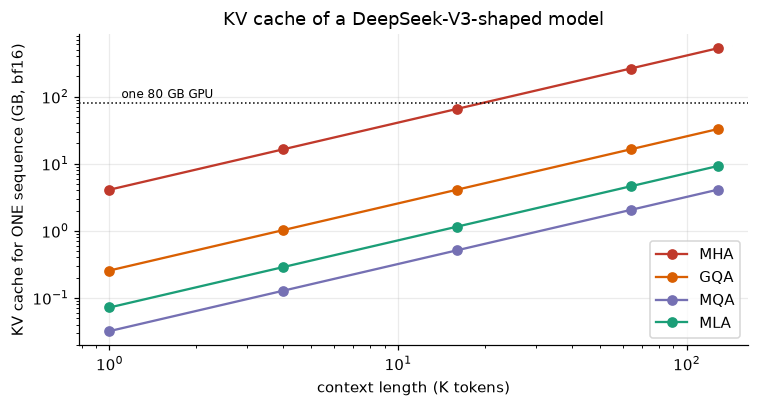

In [3]:
ctx = np.array([1, 4, 16, 64, 128]) * 1024
fig, ax = plt.subplots(figsize=(7, 3.8))
for (kind, a, b, _), col in zip(rows, [C["red"], C["orange"], C["purple"], C["green"]]):
    ax.plot(ctx / 1024, b * ctx / 1e9, "o-", color=col, label=kind)
ax.set(xscale="log", yscale="log", xlabel="context length (K tokens)", ylabel="KV cache for ONE sequence (GB, bf16)",
       title="KV cache of a DeepSeek-V3-shaped model")
ax.axhline(80, color="k", ls=":", lw=1); ax.text(1.1, 95, "one 80 GB GPU", fontsize=8)
ax.legend(); plt.tight_layout(); plt.show()

A single 128K-token sequence would need about 520 GB of cache with MHA, far more than a GPU holds. With MLA it is about 9 GB. The cache size decides how many sequences you can decode at once, and decoding is limited by memory traffic, because every new token has to read the whole cache. That is why this one design choice moves serving cost.

These are computed from the paper's published shapes. We did not run a 671B model.

## 2. Idea one: store a low-rank latent, not keys and values

Look at what keys and values are. Each is a linear function of the same hidden state $\mathbf h_t$:
$\mathbf k_t = W^K \mathbf h_t$ and $\mathbf v_t = W^V \mathbf h_t$. Together they hold $2 n_h d_h$ numbers, but they are made from a $d$-dimensional input by just two matrices, so there is a lot of redundancy to remove.

MLA forces the redundancy explicitly. First **compress** the hidden state to a short vector $\mathbf c_t^{KV}$ of size $d_c$ (much smaller than $n_h d_h$), then **expand** it into the keys and values:

$$
\mathbf c^{KV}_t = W^{DKV}\mathbf h_t, \qquad
\mathbf k^C_t = W^{UK}\mathbf c^{KV}_t, \qquad
\mathbf v^C_t = W^{UV}\mathbf c^{KV}_t
\qquad\text{(paper eqs. 1, 2, 5)}
$$

"D" stands for down-projection, "U" for up-projection. At inference only $\mathbf c^{KV}_t$ is cached. The keys and values of all heads are rebuilt from it with $W^{UK}$ and $W^{UV}$.

![The paper's Figure 2: the MLA block is the lower right box. The shaded vectors, the latent and the RoPE key, are the only things cached.](../../assets/deepseek_v3/fig2_architecture.png)

*Figure 2 of the paper. The lower right box is MLA: the input $\mathbf h_t$ is compressed into the latent $\mathbf c_t^{KV}$ (striped = cached during inference), from which the keys $\mathbf k^C$ and values $\mathbf v^C$ of every head are produced. The extra striped vector $\mathbf k^R_t$ is explained in the next section.*

A quick check that this really limits what the keys can be. With $d_c = 8$ and 64 key channels, the keys of 100 tokens can only span an 8-dimensional space:

In [4]:
torch.manual_seed(0)
T, d, d_c_toy, n_kv_dims = 100, 64, 8, 64                      # n_kv_dims = n_h * d_h
h = torch.randn(T, d)
W_DKV = torch.randn(d_c_toy, d) / d ** .5
W_UK = torch.randn(n_kv_dims, d_c_toy) / d_c_toy ** .5
W_UV = torch.randn(n_kv_dims, d_c_toy) / d_c_toy ** .5
W_K_full = torch.randn(n_kv_dims, d) / d ** .5                # ordinary MHA key projection, for comparison

c = h @ W_DKV.T                                               # (T, d_c): THE ONLY THING WE CACHE
k_lowrank = c @ W_UK.T                                        # (T, 64)
k_plain = h @ W_K_full.T                                      # (T, 64)
rank = lambda X: int((torch.linalg.svdvals(X) > 1e-4 * torch.linalg.svdvals(X)[0]).sum())

print("rank of plain MHA keys   :", rank(k_plain), "of", n_kv_dims)
print("rank of MLA keys         :", rank(k_lowrank), "of", n_kv_dims)
print("numbers cached per token : MHA %d (K and V)  vs  MLA %d  ->  %.0fx fewer" % (2 * n_kv_dims, d_c_toy, 2 * n_kv_dims / d_c_toy))
check("MLA keys have rank <= d_c", rank(k_lowrank) <= d_c_toy)
check("plain keys are full rank", rank(k_plain) == n_kv_dims)

rank of plain MHA keys   : 64 of 64
rank of MLA keys         : 8 of 64
numbers cached per token : MHA 128 (K and V)  vs  MLA 8  ->  16x fewer
PASS - MLA keys have rank <= d_c 
PASS - plain keys are full rank 


The constraint is real: an MLA head can only produce keys from an $8$-dimensional family, not any $64$-dimensional key it wants. The bet DeepSeek-V2 and V3 make is that trained models do not need the full freedom, and the experiments in section 6 below (at toy scale) and in the V2 paper (at full scale) are what test that.

Note that keys *and* values come from **one** shared latent. That halves the cache again compared with compressing them separately.

## 3. The catch: rotary position embeddings

Attention has to know where each token sits. DeepSeek-V3 uses **rotary position embeddings (RoPE)**: before the dot product, the query of the token at position $m$ and the key of the token at position $n$ are rotated by angles proportional to $m$ and $n$. Rotations compose, so the score ends up depending only on the *offset* $n - m$:

$$
(R_m \mathbf q)^\top (R_n \mathbf k) = \mathbf q^\top R_{n-m}\, \mathbf k .
$$

Now try to use that together with the latent. Without RoPE, the attention score between a query built from $\mathbf c^Q_m$ and a key built from $\mathbf c^{KV}_n$ is

$$
(W^{UQ}\mathbf c^Q_m)^\top (W^{UK}\mathbf c^{KV}_n) = (\mathbf c^Q_m)^\top\, \underbrace{(W^{UQ\top} W^{UK})}_{\text{one fixed matrix}}\, \mathbf c^{KV}_n .
$$

The fixed matrix can be computed once and folded into the query side, so the keys **never need to be expanded**: attention can run directly on the cached latents. This is the "absorption" trick of section 4. With RoPE in between, the matrix in the middle is different for every offset:

$$
(\mathbf c^Q_m)^\top\, \underbrace{(W^{UQ\top} R_{n-m}\, W^{UK})}_{\text{depends on } n-m}\, \mathbf c^{KV}_n .
$$

Let's see that numerically for one head.

First, RoPE itself. This is the exact class used below: each pair of channels is rotated by an angle `position * theta_i`, with a different speed `theta_i` per pair.

In [5]:
def rope_inv_freq(dim: int, base: float = 10000.0) -> torch.Tensor:
    """theta_i = base^(-2i/dim): one rotation speed per pair of channels."""
    return 1.0 / (base ** (torch.arange(0, dim, 2).float() / dim))


class Rope(nn.Module):
    """Rotary position embedding on the last dim of x (shape ..., T, dim)."""

    def __init__(self, dim: int, inv_freq: torch.Tensor | None = None, mscale: float = 1.0):
        super().__init__()
        self.dim, self.mscale = dim, mscale
        self.register_buffer("inv_freq", rope_inv_freq(dim) if inv_freq is None else inv_freq.clone(), persistent=False)

    def angles(self, T: int, pos0: int = 0):
        pos = torch.arange(pos0, pos0 + T, device=self.inv_freq.device).float()
        ang = torch.outer(pos, self.inv_freq)                      # (T, dim/2)
        return ang.cos() * self.mscale, ang.sin() * self.mscale

    def apply(self, x, pos0: int = 0):
        cos, sin = self.angles(x.shape[-2], pos0)
        x1, x2 = x[..., : self.dim // 2], x[..., self.dim // 2:]
        return torch.cat([x1 * cos - x2 * sin, x2 * cos + x1 * sin], -1)

In [6]:
torch.manual_seed(1)
d_head, d_lat = 16, 8
W_UQ_h = torch.randn(d_head, d_lat) / d_lat ** .5
W_UK_h = torch.randn(d_head, d_lat) / d_lat ** .5
rope16 = Rope(d_head)

def R(delta):
    """Explicit d_head x d_head rotation matrix R_delta: RoPE at position delta applied to every basis vector."""
    cols = [rope16.apply(torch.eye(d_head)[i].view(1, 1, -1), delta)[0, 0] for i in range(d_head)]
    return torch.stack(cols, 1)

M0 = W_UQ_h.T @ W_UK_h                                         # the no-RoPE matrix: fixed
mid = {dlt: W_UQ_h.T @ R(dlt) @ W_UK_h for dlt in [0, 1, 2, 5, 50]}
print("without RoPE the middle matrix is ONE fixed 8x8 matrix. With RoPE, its distance from the offset-0 matrix:")
for dlt, Md in mid.items():
    print("   offset %2d -> %.3f" % (dlt, float((Md - mid[0]).norm())))
check("offset 0: RoPE is the identity, middle matrix equals the fixed one", torch.allclose(mid[0], M0, atol=1e-6))
check("other offsets give different middle matrices", all(float((mid[k] - mid[0]).norm()) > 0.1 for k in (1, 2, 5, 50)))

q, k = torch.randn(d_head), torch.randn(d_head)
lhs, rhs = (R(7) @ q) @ (R(19) @ k), q @ R(12) @ k
check("rotations compose: (R_7 q).(R_19 k) = q . R_12 k", abs(float(lhs - rhs)) < 1e-4, "(%.5f vs %.5f)" % (float(lhs), float(rhs)))

without RoPE the middle matrix is ONE fixed 8x8 matrix. With RoPE, its distance from the offset-0 matrix:
   offset  0 -> 0.000
   offset  1 -> 1.840
   offset  2 -> 3.069
   offset  5 -> 2.656
   offset 50 -> 4.130
PASS - offset 0: RoPE is the identity, middle matrix equals the fixed one 
PASS - other offsets give different middle matrices 
PASS - rotations compose: (R_7 q).(R_19 k) = q . R_12 k (1.59455 vs 1.59455)


So there is no single matrix to fold into the query. To keep RoPE you would have to expand every cached latent into a key and rotate it **at every step**. That reads $d_c$ numbers per cached token and multiplies them by a $d_c \times n_h d_h$ matrix, for every cached token, for every generated token. It throws the benefit of the cache away.

**DeepSeek's fix: decoupled RoPE.** Split the key and the query into two parts:

- a **content part** $\mathbf q^C, \mathbf k^C$ built from the latents with no RoPE, so the absorption trick still works;
- a **position part** $\mathbf q^R, \mathbf k^R$, small ($d^R_h = 64$ channels), rotated with RoPE. The query side has one per head. The key side has **one per token, shared by all heads**, computed straight from $\mathbf h_t$ (paper eq. 3).

The score of head $i$ is the sum of the two parts, which is the same as one dot product over the concatenated vectors (paper eqs. 4, 9, 10):

$$
\mathbf q_{t,i}^\top \mathbf k_{j,i} = \underbrace{\mathbf q^{C\top}_{t,i}\mathbf k^C_{j,i}}_{\text{content: no RoPE}} + \underbrace{\mathbf q^{R\top}_{t,i}\mathbf k^R_j}_{\text{position: RoPE}},
\qquad \text{scaled by } 1/\sqrt{d_h + d_h^R}.
$$

The cache now holds the latent $\mathbf c^{KV}$ ($d_c = 512$ numbers) plus the shared RoPE key $\mathbf k^R$ (64 numbers). That is the 576 of section 1.

## 4. The full layer, and the absorbed form

Two pieces are left: RMSNorm (the paper adds one after each latent) and the MLA layer itself. The class below follows paper equations 1 to 11 line by line. It has two forward paths that must agree:

- `forward` is the straightforward one used in training: rebuild per-head keys and values from the latent, run ordinary attention.
- `forward_absorbed` is the inference form. It never builds per-head keys or values. Because $\mathbf q^{C\top}\mathbf k^C = (\mathbf c^Q)^\top W^{UQ\top} W^{UK} \mathbf c^{KV}$, we multiply the query by $W^{UK}$ once, then take dot products **directly against the cached latents**. On the value side, $\sum_j p_j\, W^{UV}\mathbf c_j = W^{UV}\sum_j p_j\, \mathbf c_j$: average the latents first, apply $W^{UV}$ once at the end.

In [7]:
class RMSNorm(nn.Module):
    """x / rms(x) * weight  (no mean subtraction, no bias)."""

    def __init__(self, d: int, eps: float = 1e-6):
        super().__init__()
        self.w = nn.Parameter(torch.ones(d))
        self.eps = eps

    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.w

In [8]:
class MLA(nn.Module):
    """Multi-head Latent Attention (paper eqs. 1-11).

    Only c_kv (d_c numbers) and k_r (d_r numbers) per token have to be cached.
    """

    def __init__(self, d: int, n_h: int, d_h: int, d_c: int, d_cq: int, d_r: int):
        super().__init__()
        self.n_h, self.d_h, self.d_c, self.d_r = n_h, d_h, d_c, d_r
        # keys / values: compress with W_DKV, expand with W_UK / W_UV
        self.W_DKV = nn.Linear(d, d_c, bias=False)
        self.kv_norm = RMSNorm(d_c)
        self.W_UK = nn.Linear(d_c, n_h * d_h, bias=False)
        self.W_UV = nn.Linear(d_c, n_h * d_h, bias=False)
        self.W_KR = nn.Linear(d, d_r, bias=False)            # the single RoPE key shared by all heads
        # queries: also low-rank (saves activation memory in training)
        self.W_DQ = nn.Linear(d, d_cq, bias=False)
        self.q_norm = RMSNorm(d_cq)
        self.W_UQ = nn.Linear(d_cq, n_h * d_h, bias=False)
        self.W_QR = nn.Linear(d_cq, n_h * d_r, bias=False)
        self.W_O = nn.Linear(n_h * d_h, d, bias=False)
        self.rope = Rope(d_r)
        self.scale = (d_h + d_r) ** -0.5                     # 1/sqrt(d_h + d_r), eq. (10)

    def latents(self, h, pos0: int = 0):
        """What the cache stores for these tokens: c_kv (B,T,d_c) and the RoPE key k_r (B,T,d_r)."""
        c_kv = self.kv_norm(self.W_DKV(h))
        k_r = self.rope.apply(self.W_KR(h), pos0)
        return c_kv, k_r

    def queries(self, h, pos0: int = 0):
        B, T, _ = h.shape
        c_q = self.q_norm(self.W_DQ(h))
        q_c = self.W_UQ(c_q).view(B, T, self.n_h, self.d_h).transpose(1, 2)            # (B,h,T,d_h)
        q_r = self.rope.apply(self.W_QR(c_q).view(B, T, self.n_h, self.d_r).transpose(1, 2), pos0)
        return q_c, q_r

    def forward(self, h):
        """Training / prefill: expand the latent into per-head K and V and run ordinary attention."""
        B, T, _ = h.shape
        c_kv, k_r = self.latents(h)
        q_c, q_r = self.queries(h)
        k_c = self.W_UK(c_kv).view(B, T, self.n_h, self.d_h).transpose(1, 2)
        v = self.W_UV(c_kv).view(B, T, self.n_h, self.d_h).transpose(1, 2)
        q = torch.cat([q_c, q_r], -1)
        k = torch.cat([k_c, k_r.unsqueeze(1).expand(-1, self.n_h, -1, -1)], -1)
        o = F.scaled_dot_product_attention(q, k, v, is_causal=True, scale=self.scale)
        return self.W_O(o.transpose(1, 2).reshape(B, T, -1))

    def forward_absorbed(self, h, cache=None):
        """Inference: never build per-head K / V.  W_UK is folded into the query, W_UV into the output.

        cache = (c_kv, k_r) of the tokens already processed; returns (output, new_cache).
        """
        B, T, _ = h.shape
        pos0 = 0 if cache is None else cache[0].shape[1]
        c_new, kr_new = self.latents(h, pos0)
        c_kv = c_new if cache is None else torch.cat([cache[0], c_new], 1)
        k_r = kr_new if cache is None else torch.cat([cache[1], kr_new], 1)
        q_c, q_r = self.queries(h, pos0)
        W_UK = self.W_UK.weight.view(self.n_h, self.d_h, self.d_c)
        W_UV = self.W_UV.weight.view(self.n_h, self.d_h, self.d_c)
        q_abs = torch.einsum("bhtd,hdc->bhtc", q_c, W_UK)                               # query in latent space
        S = c_kv.shape[1]
        score = (q_abs @ c_kv.unsqueeze(1).transpose(-1, -2) + q_r @ k_r.unsqueeze(1).transpose(-1, -2)) * self.scale
        allowed = torch.arange(S, device=h.device)[None, :] <= (pos0 + torch.arange(T, device=h.device))[:, None]
        p = score.masked_fill(~allowed, float("-inf")).softmax(-1)                       # (B,h,T,S)
        o_lat = p @ c_kv.unsqueeze(1)                                                    # (B,h,T,d_c)
        o = torch.einsum("bhtc,hdc->bhtd", o_lat, W_UV)
        return self.W_O(o.transpose(1, 2).reshape(B, T, -1)), (c_kv, k_r)

Three checks. The first rewrites the layer a second time, straight from the paper's equations with explicit loops over heads and positions, and compares. The other two test the absorbed path: it must give the same output as the expanded path, and generating one token at a time from a growing cache must give the same output as processing the whole sequence at once.

In [9]:
torch.manual_seed(0)
mla = MLA(d=64, n_h=4, d_h=16, d_c=12, d_cq=20, d_r=8).eval()
h = torch.randn(2, 11, 64)

def mla_from_paper(m, h):
    """Eqs. (1)-(11), no tricks: loops over batch, heads and positions."""
    B, T, _ = h.shape
    rope = Rope(m.d_r)
    c_kv = m.kv_norm(h @ m.W_DKV.weight.T)                                   # (1)
    k_C = (c_kv @ m.W_UK.weight.T).view(B, T, m.n_h, m.d_h)                   # (2)
    k_R = rope.apply(h @ m.W_KR.weight.T, 0)                                  # (3)  shared by all heads
    v_C = (c_kv @ m.W_UV.weight.T).view(B, T, m.n_h, m.d_h)                   # (5)
    c_q = m.q_norm(h @ m.W_DQ.weight.T)                                      # (6)
    q_C = (c_q @ m.W_UQ.weight.T).view(B, T, m.n_h, m.d_h)                    # (7)
    q_R = rope.apply((c_q @ m.W_QR.weight.T).view(B, T, m.n_h, m.d_r).transpose(1, 2), 0)   # (8)  (B,h,T,d_r)
    out = torch.zeros(B, T, m.n_h, m.d_h)
    for b in range(B):
        for i in range(m.n_h):
            for t in range(T):
                # eq. (10): score = (q_C . k_C + q_R . k_R) / sqrt(d_h + d_r), over positions j <= t
                s = torch.stack([(q_C[b, t, i] @ k_C[b, j, i] + q_R[b, i, t] @ k_R[b, j]) for j in range(t + 1)]) / math.sqrt(m.d_h + m.d_r)
                p = s.softmax(0)
                out[b, t, i] = (p[:, None] * v_C[b, :t + 1, i]).sum(0)
    return out.reshape(B, T, -1) @ m.W_O.weight.T                             # (11)

with torch.no_grad():
    ref = mla_from_paper(mla, h)
    full = mla(h)
    absorbed, cache = mla.forward_absorbed(h)
    out, cache_i = mla.forward_absorbed(h[:, :7])                             # prefill 7 tokens ...
    outs = [out]
    for t in range(7, 11):                                                    # ... then one token at a time
        o, cache_i = mla.forward_absorbed(h[:, t:t + 1], cache_i)
        outs.append(o)
    incremental = torch.cat(outs, 1)
    h2 = h.clone(); h2[:, 6:] = torch.randn(2, 5, 64)                         # change the future ...
    causal_diff = (mla(h)[:, :6] - mla(h2)[:, :6]).abs().max()                # ... the past must not move

print("max |expanded - paper equations| :", float((full - ref).abs().max()))
print("max |absorbed - expanded|        :", float((absorbed - full).abs().max()))
print("max |incremental - full|         :", float((incremental - full).abs().max()))
print("cache shapes after 11 tokens     : latent", tuple(cache_i[0].shape), " rope key", tuple(cache_i[1].shape))
check("layer equals the paper's equations (loop version)", torch.allclose(full, ref, atol=1e-5))
check("absorbed path equals expanded path", torch.allclose(absorbed, full, atol=1e-5))
check("one-token-at-a-time decoding equals full-sequence output", torch.allclose(incremental, full, atol=1e-5))
check("causal: later tokens do not change earlier outputs", float(causal_diff) < 1e-6)
check("cache holds d_c + d_r numbers per token", cache_i[0].shape[-1] + cache_i[1].shape[-1] == 12 + 8)

max |expanded - paper equations| : 8.940696716308594e-08
max |absorbed - expanded|        : 1.1920928955078125e-07
max |incremental - full|         : 1.7881393432617188e-07
cache shapes after 11 tokens     : latent (2, 11, 12)  rope key (2, 11, 8)
PASS - layer equals the paper's equations (loop version) 
PASS - absorbed path equals expanded path 
PASS - one-token-at-a-time decoding equals full-sequence output 
PASS - causal: later tokens do not change earlier outputs 
PASS - cache holds d_c + d_r numbers per token 


In [10]:
# Parameter count at the real DeepSeek-V3 attention shape, built on the "meta" device (no memory used).
with torch.device("meta"):
    big = MLA(d=7168, n_h=128, d_h=128, d_c=512, d_cq=1536, d_r=64)
n_mla = sum(p.numel() for p in big.parameters())
n_mha = 4 * 7168 * (128 * 128)                        # W_Q, W_K, W_V, W_O of plain MHA with the same heads
print(f"parameters in ONE attention layer, V3 shapes:  MLA {n_mla/1e6:.1f}M   plain MHA {n_mha/1e6:.1f}M")
print(f"x61 layers: MLA {61*n_mla/1e9:.2f}B   MHA {61*n_mha/1e9:.2f}B")
check("MLA layer has fewer parameters than same-head MHA", n_mla < n_mha)

parameters in ONE attention layer, V3 shapes:  MLA 187.1M   plain MHA 469.8M
x61 layers: MLA 11.41B   MHA 28.66B
PASS - MLA layer has fewer parameters than same-head MHA 


MLA also has **fewer parameters** than MHA with the same heads, so the cache saving is not paid for with a bigger layer.

The query is compressed too ($W^{DQ}$ down to 1536, then $W^{UQ}$ back up). That does not change the cache at all. The paper says it reduces the *activation memory during training*, because the 1536-dim latent is what has to be kept for the backward pass instead of the full $n_h d_h = 16384$-dim query.

## 5. What the trade costs: arithmetic per cached byte

Nothing is free. In the absorbed form every head does its dot products in the **latent** space ($d_c + d_r = 576$ dimensions) rather than the head space ($d_h + d_r = 192$), so decoding does more multiplications. That can still be a win because autoregressive decoding with a long cache spends most of its time **waiting for memory**, not multiplying.

Count the floating-point operations per generated token and the cache elements that must be read, for one layer of the V3 shapes:

In [11]:
# per generated token, per layer, for ONE cached token (multiply-add = 2 FLOPs)
# MHA : every head reads its own K and V (2 d_h numbers) and does a score (d_h) and a value (d_h) product
mha_flops = n_h * (2 * d_h + 2 * d_h)
mha_read = 2 * n_h * d_h
# MLA (absorbed): all heads share ONE (d_c + d_r)-number cache entry
#   score per head: (d_c + d_r) multiply-adds; value per head: d_c
mla_flops = n_h * (2 * (d_c + d_r) + 2 * d_c)
mla_read = d_c + d_r

print(f"{'':5s} {'FLOPs per cached token':>24s} {'elements read':>15s} {'FLOPs per element':>19s} {'FLOPs per byte (bf16)':>23s}")
for name, f, r_ in [("MHA", mha_flops, mha_read), ("MLA", mla_flops, mla_read)]:
    print(f"{name:5s} {f:24,d} {r_:15,d} {f / r_:19.1f} {f / (r_ * BYTES):23.1f}")
print(f"\nMLA does {mla_flops / mha_flops:.1f}x the arithmetic per cached token and reads {mha_read / mla_read:.1f}x fewer elements.")
print("A current data-center GPU needs roughly 300 FLOPs per byte (spec sheets: ~1000 TFLOPS bf16 over ~3.4 TB/s)")
print("before arithmetic, not memory, becomes the bottleneck.")
check("MLA does more arithmetic per generated token than MHA", mla_flops > mha_flops)
check("...but reads 57x fewer cache elements", abs(mha_read / mla_read - 56.9) < 0.1)

        FLOPs per cached token   elements read   FLOPs per element   FLOPs per byte (bf16)
MHA                     65,536          32,768                 2.0                     1.0
MLA                    278,528             576               483.6                   241.8

MLA does 4.2x the arithmetic per cached token and reads 56.9x fewer elements.
A current data-center GPU needs roughly 300 FLOPs per byte (spec sheets: ~1000 TFLOPS bf16 over ~3.4 TB/s)
before arithmetic, not memory, becomes the bottleneck.
PASS - MLA does more arithmetic per generated token than MHA 
PASS - ...but reads 57x fewer cache elements 


MHA decoding does about one FLOP per byte it reads, so the arithmetic units sit idle waiting for memory. MLA does a couple of hundred, which moves a decode step from deeply memory-bound towards balanced. That is the real argument for the design: use the idle arithmetic to save memory traffic.

This is a counting argument. Whether it becomes wall-clock speed depends on the kernels and the GPU, which we cannot measure on a laptop CPU. What we can check is the other half, that more arithmetic really is the price: time one decode step of both layers on this CPU with a long cache.

In [12]:
torch.manual_seed(0)
B_, S_, nh_, dh_, dc_, dr_, d_ = 2, 8192, 16, 64, 128, 32, 1024      # a scaled-down shape
mla_s = MLA(d=d_, n_h=nh_, d_h=dh_, d_c=dc_, d_cq=256, d_r=dr_).eval()
h_new = torch.randn(B_, 1, d_)
cache_mla = (torch.randn(B_, S_, dc_), torch.randn(B_, S_, dr_))
K_cache, V_cache = torch.randn(B_, nh_, S_, dh_), torch.randn(B_, nh_, S_, dh_)
q_new = torch.randn(B_, nh_, 1, dh_)

def step_mha():
    return F.scaled_dot_product_attention(q_new, K_cache, V_cache)            # one decode step, no mask needed

def step_mla():
    return mla_s.forward_absorbed(h_new, cache_mla)[0]

def bench(fn, reps=20):
    with torch.no_grad():
        fn(); fn()
        ts = []
        for _ in range(reps):
            t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return 1000 * float(np.median(ts))

t_mha, t_mla = bench(step_mha), bench(step_mla)
mb = lambda n: n * 4 / 1e6
print(f"cache read per step : MHA {mb(2 * B_ * nh_ * S_ * dh_):.0f} MB    MLA {mb(B_ * S_ * (dc_ + dr_)):.0f} MB")
print(f"decode step on CPU  : MHA {t_mha:.2f} ms    MLA absorbed {t_mla:.2f} ms")

cache read per step : MHA 134 MB    MLA 10 MB
decode step on CPU  : MHA 5.33 ms    MLA absorbed 81.69 ms


Read this with care. A CPU has slow arithmetic relative to its memory, the opposite balance from a GPU decoding a large batch. Here the extra arithmetic of MLA shows up directly in the time. This shows the **price** side of the trade. The **benefit** side (a 57x smaller cache that fits more sequences and is read faster) needs the GPU regime that the FLOPs-per-byte table describes.

## 6. Does the compression hurt quality?

The latent limits what keys and values can be (section 2), so the layer is less expressive than full MHA at the same width. DeepSeek-V2 and V3 report that MLA holds up at scale. At our scale we can only ask the same question on a toy: train three small character-level language models that differ only in attention, on a 460K-character corpus (the prose of this repository's notebooks and docs), and compare held-out loss.

- **MHA**: 4 heads of 24, caches $2 \cdot 4 \cdot 24 = 192$ numbers per token per layer.
- **MLA, $d_c = 24$**: caches $24 + 12 = 36$ numbers (5.3x fewer).
- **MLA, $d_c = 48$**: caches $48 + 12 = 60$ numbers (3.2x fewer).

Two seeds each, 300 steps of 48 sequences of 64 characters. (The model is deliberately tiny: 96 wide, 3 layers. This laptop is shared, so the budget is small.)

In [13]:
data = K.CharData()
print("corpus: %d characters, vocabulary %d, train/val %d/%d" % (len(data.train) + len(data.val), data.vocab, len(data.train), len(data.val)))

base = dict(vocab=data.vocab, d=96, n_layers=3, n_heads=4, d_ff=192)
configs = {
    "MHA": K.LMConfig(**base, attn="mha"),
    "MLA d_c=24": K.LMConfig(**base, attn="mla", d_c=24, d_cq=36, d_r=12),
    "MLA d_c=48": K.LMConfig(**base, attn="mla", d_c=48, d_cq=36, d_r=12),
}
cache_numbers = {"MHA": 2 * 4 * 24, "MLA d_c=24": 24 + 12, "MLA d_c=48": 48 + 12}
results = {}
t0 = time.time()
for name, cfg in configs.items():
    vals = []
    for seed in range(2):
        model, hist = K.train_lm(cfg, data, steps=300, B=48, T=64, lr=4e-3, seed=seed)
        vals.append(K.evaluate(model, data, T=64, n_batches=10)["main"])
    n_params = sum(p.numel() for p in model.parameters())
    results[name] = (np.array(vals), n_params)
    print(f"{name:11s} val loss {np.mean(vals):.3f} +- {np.std(vals):.3f}   params {n_params/1e6:.2f}M   cache {cache_numbers[name]:3d} numbers/token/layer")
print("training time: %.0f s" % (time.time() - t0))

corpus: 460152 characters, vocabulary 96, train/val 414136/46016


MHA         val loss 2.449 +- 0.009   params 0.29M   cache 192 numbers/token/layer


MLA d_c=24  val loss 2.500 +- 0.010   params 0.25M   cache  36 numbers/token/layer


MLA d_c=48  val loss 2.537 +- 0.008   params 0.27M   cache  60 numbers/token/layer
training time: 278 s


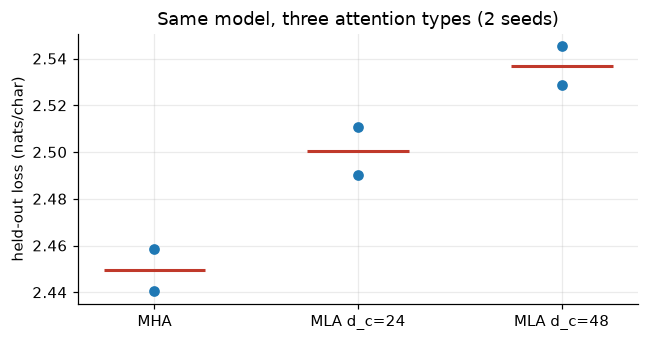

gap MLA(24) - MHA: +0.051 nats;   gap MLA(48) - MHA: +0.088 nats;   largest seed spread: 0.010
PASS - all three models learn (loss below ln(vocab) - 1.5) 
PASS - MLA with the larger latent is within 0.1 nats of MHA 
PASS - MLA with a 5.3x smaller cache is within 0.15 nats of MHA 


In [14]:
fig, ax = plt.subplots(figsize=(6, 3.2))
for i, (name, (v, _)) in enumerate(results.items()):
    ax.scatter([i] * len(v), v, color=C["blue"], zorder=3)
    ax.hlines(v.mean(), i - .25, i + .25, color=C["red"], lw=2)
ax.set_xticks(range(3)); ax.set_xticklabels(results.keys()); ax.set(ylabel="held-out loss (nats/char)", title="Same model, three attention types (2 seeds)")
plt.tight_layout(); plt.show()

m_mha, m_32, m_64 = (results[k][0] for k in ["MHA", "MLA d_c=24", "MLA d_c=48"])
spread = max(r[0].std() for r in results.values())
print(f"gap MLA(24) - MHA: {m_32.mean() - m_mha.mean():+.3f} nats;   gap MLA(48) - MHA: {m_64.mean() - m_mha.mean():+.3f} nats;   largest seed spread: {spread:.3f}")
check("all three models learn (loss below ln(vocab) - 1.5)", all(r[0].mean() < math.log(data.vocab) - 1.5 for r in results.values()))
check("MLA with the larger latent is within 0.1 nats of MHA", abs(m_64.mean() - m_mha.mean()) < 0.1)
check("MLA with a 5.3x smaller cache is within 0.15 nats of MHA", abs(m_32.mean() - m_mha.mean()) < 0.15)

## What to take away

1. **MLA caches one shared latent per token, not per-head keys and values.** For V3's shapes that is 576 instead of 32,768 numbers per token per layer.
2. **RoPE does not commute with the up-projection**, so the layer keeps a small separate RoPE key (64 channels, shared by all heads) next to the latent. Everything else is position-free and can be absorbed into the query and output projections.
3. **The price is arithmetic**, not parameters: absorbed decoding does several times more FLOPs per cached token than MHA, which is cheap on hardware that is waiting for memory.
4. The layer here is verified three ways: against a loop written from the paper's equations, absorbed versus expanded, and incremental versus full-sequence decoding.

## What this notebook does not show
- **No full-scale result.** The cache sizes and FLOPs per byte are computed from the paper's shapes. Nothing here was run at 671B scale, and the claim that MLA matches MHA in quality at scale is not reproduced. Our toy comparison (300 steps, a 96-wide model, 2 seeds) found MLA **slightly worse** than MHA: +0.05 nats with the 5.3x smaller cache and +0.09 with the larger latent, both larger than the seed spread (about 0.01). So at this scale the layer trains and lands in the same range, but we do not reproduce 'matches MHA'. The larger latent doing worse than the smaller one is not what we would expect and is most likely undertraining noise (two seeds); we did not investigate.
- **No GPU timing.** The decode benchmark is on a CPU, which has the wrong balance of compute and memory bandwidth to show the benefit.
- **Left out:** the extra scaling the paper applies at width bottlenecks, and the FP8 kernels MLA runs on in production.

*Next:* notebook 2 builds the DeepSeekMoE feed-forward layer.

In [15]:
print("passed:", len(PASS), "| failed:", len(FAIL))
assert not FAIL, FAIL

passed: 20 | failed: 0
